# WY2021 seasonal-site SNOWPACK comparison

Compare the site-specific HRRR-AK lapse-rate soil baseline with the 1,000 m and 500 m TopoPyScale cases at **PPSA, TRAM, and HEEN**. The runs share the existing 28-layer soil initialization, the site's configured slope, a 1.2 °C rain–snow threshold, and identical WY2020 lapse-rate forcing. The comparison uses all WY2021 hours after the forcing branches. The [forcing preparation notebook](01_prepare_WY2021_seasonal_topopyscale.ipynb) shows the inputs and cell-elevation offsets.

This is a first comparison using the supplied downscaled radiation and temperature with the existing site configuration. In steep coastal terrain, a cell can average terrain far below the model site. TRAM's large grid-to-site elevation offsets are recorded below.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd()
candidates = [cwd]
for parent in (cwd, *cwd.parents):
    candidates.extend((parent / "modeling/downscaling",
                       parent / "juneau_snow_modeling_manuscript/modeling/downscaling"))
folder = next((p for p in candidates if (p / "run_seasonal_topopyscale.py").is_file()), None)
if folder is None:
    raise FileNotFoundError("Open from the manuscript repository or the repos workspace.")
sys.path.insert(0, str(folder))
from run_seasonal_topopyscale import RESOLUTIONS, SITES, YEAR, locations, model_output, read_smet

labels = {None:"HRRR-AK lapse-rate", 1000:"TopoPyScale 1,000 m", 500:"TopoPyScale 500 m"}
colors = {None:"#525252",1000:"#bc551d",500:"#006f79"}
models, result = {}, []
for site in SITES:
    for m in (None,*RESOLUTIONS):
        parent, base, test = locations(site,m)
        stem = base if m is None else test
        path = parent / "output" / f"{stem.name}_soil.smet"
        data = model_output(path).loc[YEAR[0]:YEAR[-1]]
        if not data.index.equals(YEAR) or not np.isfinite(data[["depth_m","swe_mm"]]).all().all():
            raise ValueError(f"Incomplete WY2021 model output: {path}")
        models[site,m] = data
        peak = data.swe_mm.idxmax()
        result.append({"Site":site.upper(),"Forcing":labels[m],"Peak depth (m)":data.depth_m.max(),
                       "Peak SWE (mm w.e.)":data.swe_mm.max(),"Peak SWE date (UTC)":peak.date(),
                       "Mean depth (m)":data.depth_m.mean()})


## WY2021 snow depth with station observations

The black lines use the station snow depth records from [Figure 4](../../figures/notebooks/figure4_presentation.ipynb). Both model and station curves are daily means. Days with no station measurements remain gaps. The PPSA snow-pit observations in Figure 4 are from WY2025 and fall outside this comparison.

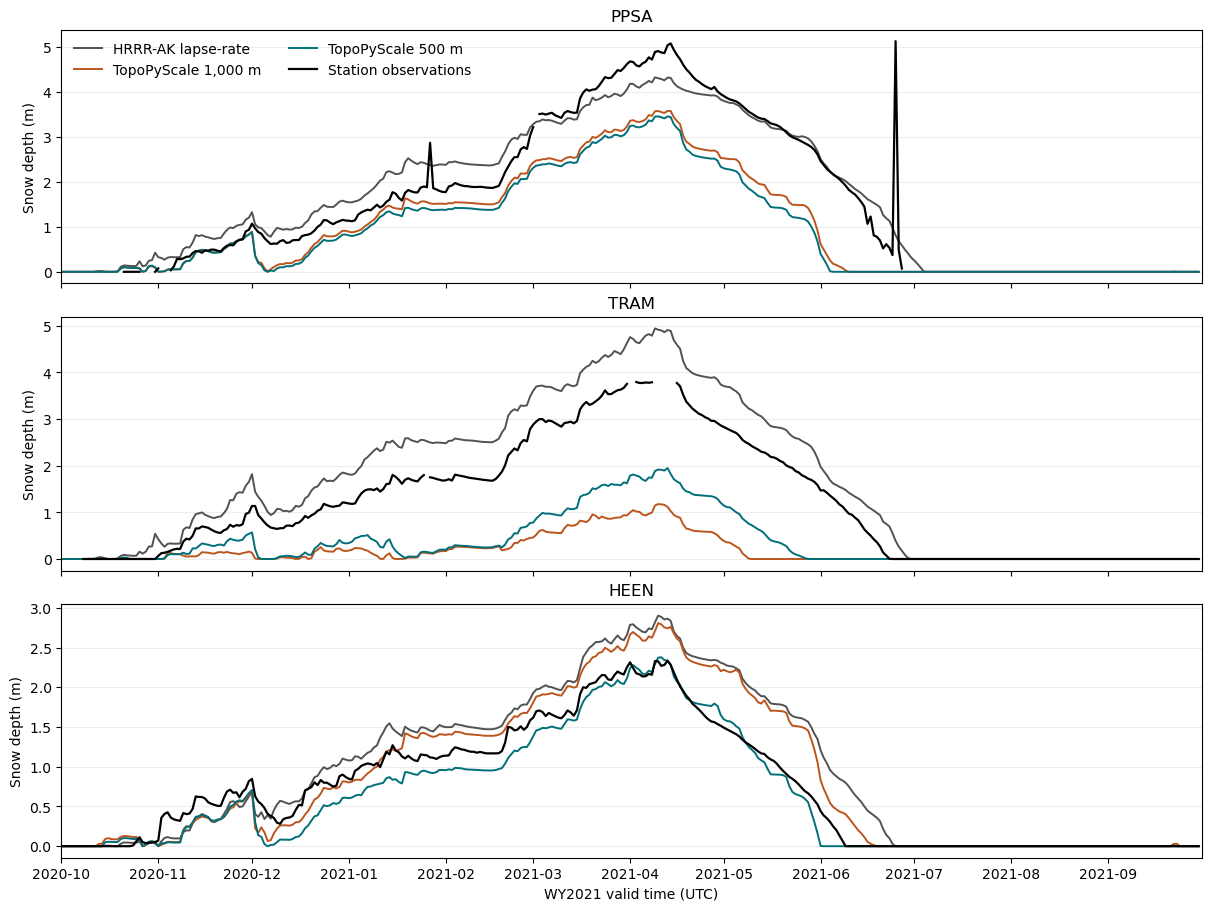

,First observation (UTC),Last observation (UTC),Valid measurements,Days with observations
Site,,,,
PPSA,2020-10-21 08:00:00,2021-06-27 04:00:00,5256,242
TRAM,2020-10-08 21:00:00,2021-09-30 23:00:00,8197,348
HEEN,2020-10-01 00:00:00,2021-09-30 23:00:00,7935,365


In [2]:
import xarray as xr

station_root = Path("/hdd/snow_hydrology/met_station")
station_files = {
    "ppsa": "ppsa2/pppsa_met_station_data_synoptic_2026-03-20",
    "tram": "tram/tram_met_station_data_synoptic_2026-03-20",
    "heen": "snotel/heenlatinee/heen_met_2016_2026_cleaned_v1.nc",
}
observed = {}
coverage = []
for site, name in station_files.items():
    with xr.open_dataset(station_root / name) as station:
        if station.hs.attrs.get("units") != "cm":
            raise ValueError(f"Unexpected snow depth units for {site.upper()}")
        values = station.hs.to_series().sort_index().loc[YEAR[0]:YEAR[-1]] / 100
    valid = values.dropna()
    if valid.empty:
        continue
    observed[site] = values.resample("D").mean()
    coverage.append({"Site": site.upper(), "First observation (UTC)": valid.index[0],
                     "Last observation (UTC)": valid.index[-1],
                     "Valid measurements": len(valid),
                     "Days with observations": observed[site].count()})

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, layout="constrained")
legend = {}
for ax, site in zip(axes, SITES):
    for m in (None, *RESOLUTIONS):
        depth = models[site,m].depth_m.resample("D").mean()
        line, = ax.plot(depth.index, depth, color=colors[m], lw=1.4, label=labels[m])
        legend[labels[m]] = line
    if site in observed:
        line, = ax.plot(observed[site].index, observed[site], color="black", lw=1.6,
                        label="Station observations", zorder=5)
        legend["Station observations"] = line
    else:
        ax.text(.99, .95, "No WY2021 station data", transform=ax.transAxes, ha="right", va="top")
    ax.set(title=site.upper(), ylabel="Snow depth (m)", xlim=(YEAR[0], YEAR[-1]))
    ax.grid(axis="y", alpha=.22)
axes[0].legend(legend.values(), legend.keys(), frameon=False, ncol=2)
axes[-1].set_xlabel("WY2021 valid time (UTC)")
plt.show()
display(pd.DataFrame(coverage).set_index("Site"))


## Seasonal summary and forcing elevations

In [3]:
summary = pd.DataFrame(result)
base_peak = summary[summary.Forcing == labels[None]].set_index("Site")["Peak SWE (mm w.e.)"]
summary["Peak SWE change from baseline (mm)"] = summary["Peak SWE (mm w.e.)"] - summary.Site.map(base_peak)
display(summary.set_index(["Site","Forcing"]).round(2))

cells = []
for site in SITES:
    for m in RESOLUTIONS:
        _, _, test = locations(site,m)
        meta = json.loads(test.with_suffix(".json").read_text())
        cells.append({"Site":site.upper(),"Forcing":labels[m],"Site elevation (m)":meta["site_elevation_m"],
                      "Cell elevation (m)":meta["grid_elevation_m"],"Cell minus site (m)":meta["cell_minus_site_m"],
                      "Profile fallback hours":meta["profile_fallback_hours"]})
display(pd.DataFrame(cells).set_index(["Site","Forcing"]).round(1))


Peak depth (m)  Peak SWE (mm w.e.)  \
Site Forcing                                                   
PPSA HRRR-AK lapse-rate             4.35             1690.49   
     TopoPyScale 1,000 m            3.61             1310.53   
     TopoPyScale 500 m              3.49             1257.16   
TRAM HRRR-AK lapse-rate             4.97             1984.64   
     TopoPyScale 1,000 m            1.20              476.59   
     TopoPyScale 500 m              2.00              809.81   
HEEN HRRR-AK lapse-rate             2.93             1064.03   
     TopoPyScale 1,000 m            2.83              982.31   
     TopoPyScale 500 m              2.42              799.66   

                         Peak SWE date (UTC)  Mean depth (m)  \
Site Forcing                                                   
PPSA HRRR-AK lapse-rate           2021-05-06            1.59   
     TopoPyScale 1,000 m          2021-04-15            0.97   
     TopoPyScale 500 m            2021-04-18            0.90   
TRAM HRRR-AK lapse-rate           2021-04-18            1.65   
     TopoPyScale 1,000 m          2021-04-13            0.18   
     TopoPyScale 500 m            2021-04-14            0.36   
HEEN HRRR-AK lapse-rate           2021-04-30            0.93   
     TopoPyScale 1,000 m          2021-05-04            0.84   
     TopoPyScale 500 m            2021-04-16            0.60   

                          Peak SWE change from baseline (mm)  
Site Forcing                                                  
PPSA HRRR-AK lapse-rate                                 0.00  
     TopoPyScale 1,000 m                             -379.95  
     TopoPyScale 500 m                               -433.33  
TRAM HRRR-AK lapse-rate                                 0.00  
     TopoPyScale 1,000 m                            -1508.06  
     TopoPyScale 500 m                              -1174.83  
HEEN HRRR-AK lapse-rate                                 0.00  
     TopoPyScale 1,000 m                              -81.72  
     TopoPyScale 500 m                               -264.37

Site elevation (m)  Cell elevation (m)  \
Site Forcing                                                       
PPSA TopoPyScale 1,000 m               670.0               766.6   
     TopoPyScale 500 m                 670.0               717.0   
TRAM TopoPyScale 1,000 m               529.0                97.4   
     TopoPyScale 500 m                 529.0               289.3   
HEEN TopoPyScale 1,000 m               640.1               812.8   
     TopoPyScale 500 m                 640.1               689.5   

                          Cell minus site (m)  Profile fallback hours  
Site Forcing                                                           
PPSA TopoPyScale 1,000 m                 96.6                       0  
     TopoPyScale 500 m                   47.0                       0  
TRAM TopoPyScale 1,000 m               -431.6                       0  
     TopoPyScale 500 m                 -239.7                       0  
HEEN TopoPyScale 1,000 m                172.8                       0  
     TopoPyScale 500 m                   49.5                       0